<a href="https://colab.research.google.com/github/fitridianamusa/Artikel-ADW-Kelompok-8/blob/main/GARCH_LSTM_NEW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **IMPORT LIBRARY**

In [1]:
%pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 18.4 MB/s  0:00:00


In [2]:
# ============================================
# 1. IMPORT LIBRARY
# ============================================

# Pengolahan data
import numpy as np
import pandas as pd

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Pengujian stasioneritas dan diagnostik
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

# Pemodelan GARCH
from arch import arch_model

# Pemodelan LSTM
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler

# Evaluasi model
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

# Pemeriksaan hasil dan peringatan
import warnings
warnings.filterwarnings("ignore")

# Reproduksibilitas
np.random.seed(123)
tf.random.set_seed(123)

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

print("Seluruh library berhasil diimpor.")
print("Versi pandas:", pd.__version__)
print("Versi TensorFlow:", tf.__version__)

Seluruh library berhasil diimpor.
Versi pandas: 2.2.3
Versi TensorFlow: 2.21.0


## **LOAD DATA**

In [3]:
# ============================================
# 2. MEMBACA DATA DARI GITHUB
# ============================================

url = (
    "https://raw.githubusercontent.com/"
    "fitridianamusa/Artikel-ADW-Kelompok-8/"
    "main/Data%20Historis%20USD_IDR.csv"
)

df = pd.read_csv(url, encoding="utf-8-sig")

print("Ukuran data:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi struktur data:")
df.info()

Ukuran data: (1442, 7)

Nama kolom:
['Tanggal', 'Terakhir', 'Pembukaan', 'Tertinggi', 'Terendah', 'Vol.', 'Perubahan%']

Lima baris pertama:


,Tanggal,Terakhir,Pembukaan,Tertinggi,Terendah,Vol.,Perubahan%
0,01/09/2026,"17.715,0","17.725,0","17.735,0","17.704,5",NaN,"0,00%"
1,31/08/2026,"17.715,0","17.750,0","17.770,0","17.712,5",NaN,"0,14%"
2,28/08/2026,"17.690,0","17.715,0","17.722,5","17.679,0",NaN,"-0,17%"
3,27/08/2026,"17.720,0","17.760,0","17.790,0","17.720,0",NaN,"0,11%"
4,26/08/2026,"17.700,0","17.695,0","17.733,5","17.677,5",NaN,"-0,06%"



Informasi struktur data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1442 entries, 0 to 1441
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Tanggal     1442 non-null   object
 1   Terakhir    1442 non-null   object
 2   Pembukaan   1442 non-null   object
 3   Tertinggi   1442 non-null   object
 4   Terendah    1442 non-null   object
 5   Vol.        502 non-null    object
 6   Perubahan%  1442 non-null   object
dtypes: object(7)
memory usage: 79.0+ KB


In [4]:
# ============================================
# 3. PEMBERSIHAN DATA
# ============================================

# Menghapus spasi pada nama kolom
df.columns = df.columns.str.strip()

# Menampilkan nama kolom untuk pemeriksaan
print("Kolom yang tersedia:", df.columns.tolist())

# Menyesuaikan nama kolom tanggal
kolom_tanggal = next(
    (
        col for col in df.columns
        if col.lower().strip() in ["tanggal", "date", "datetime"]
    ),
    None
)

# Menyesuaikan nama kolom harga penutupan
kolom_harga = next(
    (
        col for col in df.columns
        if col.lower().strip() in [
            "terakhir", "last", "close", "closing price"
        ]
    ),
    None
)

if kolom_tanggal is None:
    raise ValueError(
        "Kolom tanggal tidak ditemukan. Periksa nama kolom CSV."
    )

if kolom_harga is None:
    raise ValueError(
        "Kolom harga penutupan tidak ditemukan. "
        "Periksa nama kolom CSV."
    )

# Mengambil tanggal dan harga penutupan
data = df[[kolom_tanggal, kolom_harga]].copy()
data.columns = ["Tanggal", "Kurs"]

# Mengubah tanggal menjadi format datetime
data["Tanggal"] = pd.to_datetime(
    data["Tanggal"],
    dayfirst=True,
    errors="coerce"
)

# Fungsi untuk membersihkan format angka
def konversi_angka(x):
    if pd.isna(x):
        return np.nan

    if isinstance(x, (int, float, np.number)):
        return float(x)

    x = str(x).strip()
    x = x.replace(" ", "")

    # Mengakomodasi format Indonesia:
    # 16.500,25 -> 16500.25
    if "," in x and "." in x:
        if x.rfind(",") > x.rfind("."):
            x = x.replace(".", "").replace(",", ".")
        else:
            x = x.replace(",", "")

    # Mengakomodasi angka desimal dengan koma
    elif "," in x:
        x = x.replace(",", ".")

    # Menghapus karakter lain yang tidak relevan
    x = x.replace("%", "")

    try:
        return float(x)
    except ValueError:
        return np.nan

data["Kurs"] = data["Kurs"].apply(konversi_angka)

# Menghapus observasi yang tidak valid
data = data.dropna(subset=["Tanggal", "Kurs"])
data = data[data["Kurs"] > 0]

# Menghapus duplikasi tanggal
data = data.drop_duplicates(subset="Tanggal", keep="first")

# Mengurutkan data dari tanggal terlama ke terbaru
data = data.sort_values("Tanggal").reset_index(drop=True)

print("Ukuran data setelah pembersihan:", data.shape)
print("\nPeriode data:")
print("Awal :", data["Tanggal"].min())
print("Akhir:", data["Tanggal"].max())

print("\nRingkasan data:")
display(data.describe())

print("\nLima observasi pertama:")
display(data.head())

Kolom yang tersedia: ['Tanggal', 'Terakhir', 'Pembukaan', 'Tertinggi', 'Terendah', 'Vol.', 'Perubahan%']
Ukuran data setelah pembersihan: (1442, 2)

Periode data:
Awal : 2021-01-01 00:00:00
Akhir: 2026-09-01 00:00:00

Ringkasan data:


,Tanggal,Kurs
count,1442,1442.000000
mean,2023-11-15 20:24:17.975034880,15601.574549
min,2021-01-01 00:00:00,13880.000000
25%,2022-06-24 18:00:00,14705.000000
50%,2023-11-27 12:00:00,15572.500000
75%,2025-04-14 18:00:00,16330.000000
max,2026-09-01 00:00:00,18175.000000
std,NaN,1024.339256



Lima observasi pertama:


,Tanggal,Kurs
0,2021-01-01,14213.7
1,2021-01-04,13885.0
2,2021-01-05,13900.0
3,2021-01-06,13880.0
4,2021-01-07,13890.0


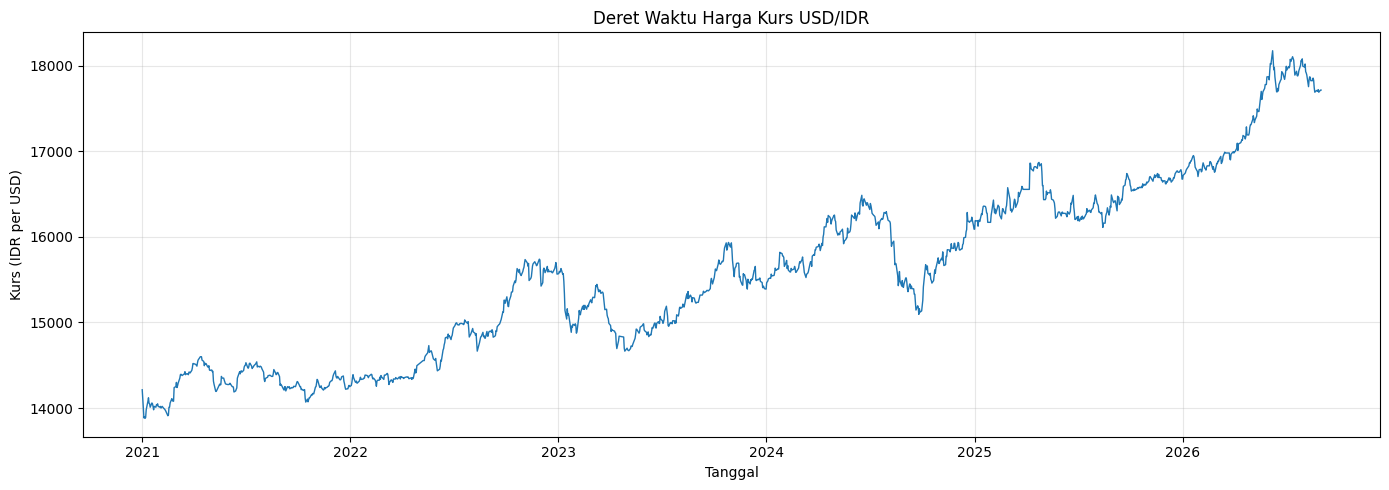

In [5]:
# ============================================
# 4. PLOT HARGA KURS
# ============================================

plt.figure(figsize=(14, 5))

plt.plot(
    data["Tanggal"],
    data["Kurs"],
    linewidth=1
)

plt.title("Deret Waktu Harga Kurs USD/IDR")
plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Lima baris pertama data return:


,Tanggal,Kurs,Log_Return
0,2021-01-04,13885.0,-0.023397
1,2021-01-05,13900.0,0.001080
2,2021-01-06,13880.0,-0.001440
3,2021-01-07,13890.0,0.000720
4,2021-01-08,13980.0,0.006459



Statistik deskriptif log return:


,Log_Return
count,1441.000000
mean,0.000153
std,0.003182
min,-0.023397
25%,-0.001237
50%,0.000000
75%,0.001891
max,0.018256


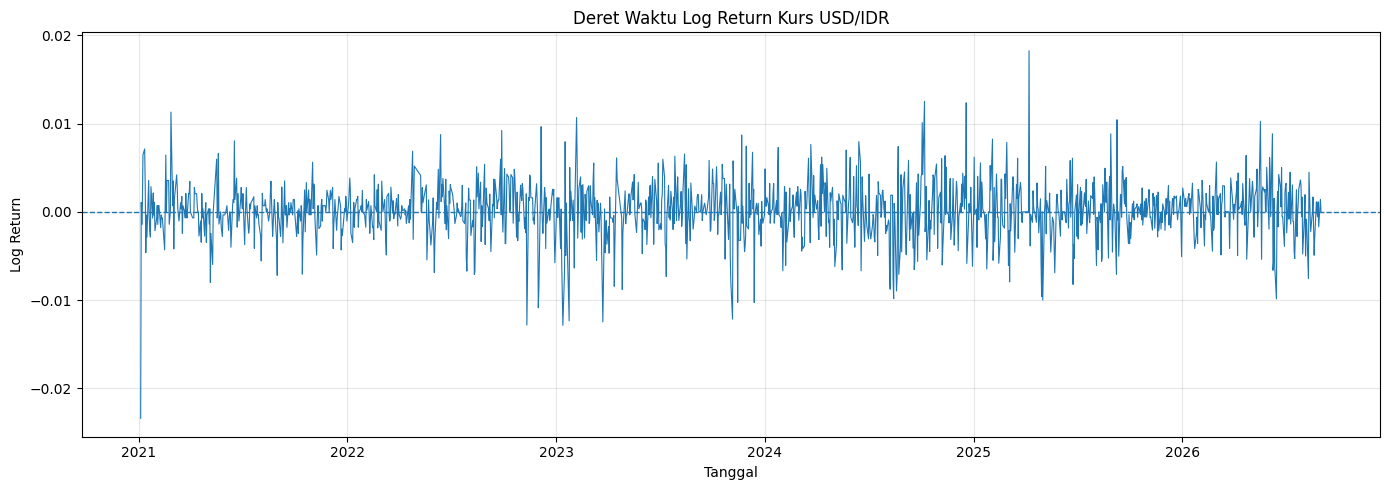

In [6]:
# ============================================
# 5. TRANSFORMASI LOG RETURN
# ============================================

data["Log_Return"] = np.log(data["Kurs"]).diff()

# Menghapus observasi pertama yang tidak memiliki return
data_return = data.dropna(subset=["Log_Return"]).copy()
data_return = data_return.reset_index(drop=True)

print("Lima baris pertama data return:")
display(data_return.head())

print("\nStatistik deskriptif log return:")
display(data_return["Log_Return"].describe())

# Plot log return
plt.figure(figsize=(14, 5))

plt.plot(
    data_return["Tanggal"],
    data_return["Log_Return"],
    linewidth=0.8
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Deret Waktu Log Return Kurs USD/IDR")
plt.xlabel("Tanggal")
plt.ylabel("Log Return")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# ============================================
# 6. TRAINING DAN TESTING
# ============================================

proporsi_train = 0.80

n = len(data_return)
batas = int(n * proporsi_train)

train = data_return.iloc[:batas].copy()
test = data_return.iloc[batas:].copy()

r_train = train["Log_Return"].copy()
r_test = test["Log_Return"].copy()

print("Jumlah observasi seluruh data:", n)
print("Jumlah training:", len(train))
print("Jumlah testing :", len(test))

print("\nPeriode training:")
print(train["Tanggal"].min(), "sampai", train["Tanggal"].max())

print("\nPeriode testing:")
print(test["Tanggal"].min(), "sampai", test["Tanggal"].max())

Jumlah observasi seluruh data: 1441
Jumlah training: 1152
Jumlah testing : 289

Periode training:
2021-01-04 00:00:00 sampai 2025-07-23 00:00:00

Periode testing:
2025-07-24 00:00:00 sampai 2026-09-01 00:00:00


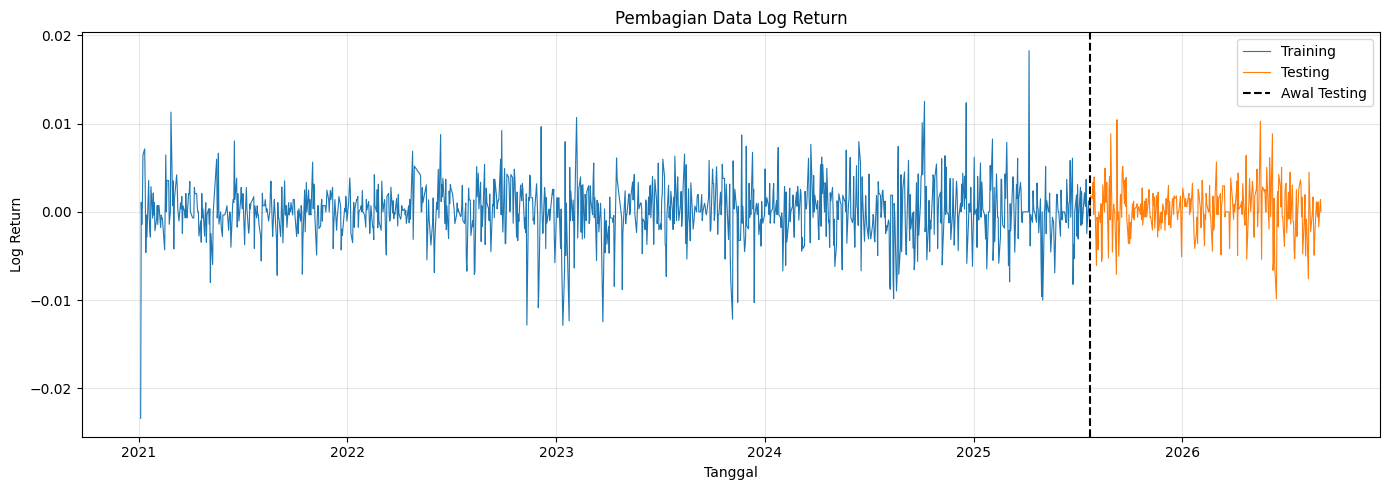

In [8]:
# ============================================
# VISUALISASI TRAINING DAN TESTING
# ============================================

plt.figure(figsize=(14, 5))

plt.plot(
    train["Tanggal"],
    train["Log_Return"],
    label="Training",
    linewidth=0.8
)

plt.plot(
    test["Tanggal"],
    test["Log_Return"],
    label="Testing",
    linewidth=0.8
)

plt.axvline(
    test["Tanggal"].iloc[0],
    color="black",
    linestyle="--",
    label="Awal Testing"
)

plt.title("Pembagian Data Log Return")
plt.xlabel("Tanggal")
plt.ylabel("Log Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# ============================================
# 7. UJI ADF
# ============================================

hasil_adf = adfuller(r_train.dropna(), autolag="AIC")

print("ADF Statistic :", hasil_adf[0])
print("p-value       :", hasil_adf[1])
print("Jumlah lag    :", hasil_adf[2])
print("Jumlah observasi:", hasil_adf[3])

alpha = 0.05

if hasil_adf[1] < alpha:
    print("Keputusan: Tolak H0.")
    print("Kesimpulan: Data return stasioner menurut uji ADF.")
else:
    print("Keputusan: Gagal menolak H0.")
    print("Kesimpulan: Bukti stasioneritas belum cukup.")

ADF Statistic : -11.703191124905155
p-value       : 1.5509827560815807e-21
Jumlah lag    : 6
Jumlah observasi: 1145
Keputusan: Tolak H0.
Kesimpulan: Data return stasioner menurut uji ADF.


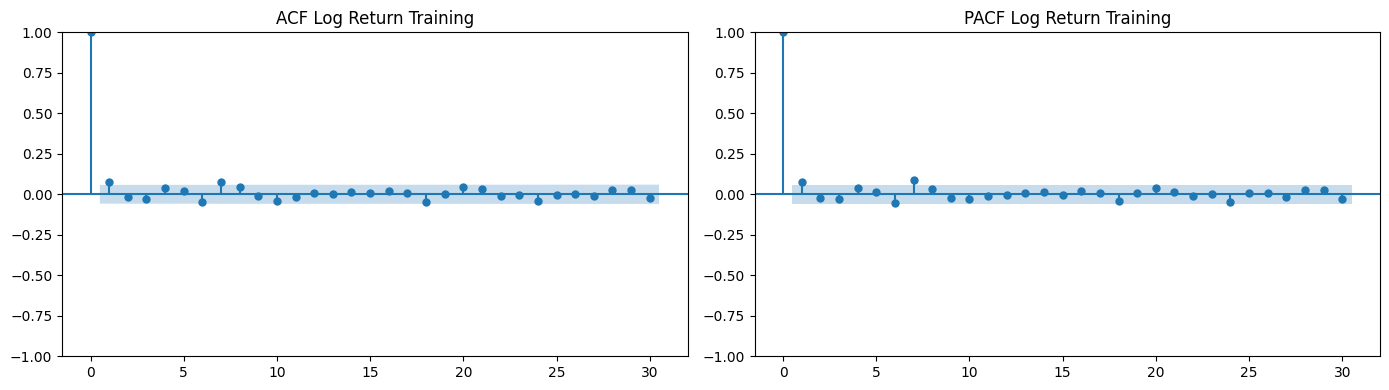

In [10]:
# ============================================
# 8A. ACF DAN PACF RETURN
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(r_train, lags=30, ax=axes[0])
axes[0].set_title("ACF Log Return Training")

plot_pacf(r_train, lags=30, ax=axes[1], method="ywm")
axes[1].set_title("PACF Log Return Training")

plt.tight_layout()
plt.show()

In [11]:
# ============================================
# 8B. UJI LJUNG-BOX RETURN
# ============================================

lb_return = acorr_ljungbox(
    r_train,
    lags=[5, 10, 20],
    return_df=True
)

display(lb_return)

,lb_stat,lb_pvalue
5,10.541504,0.061268
10,24.667386,0.006013
20,30.411648,0.063452


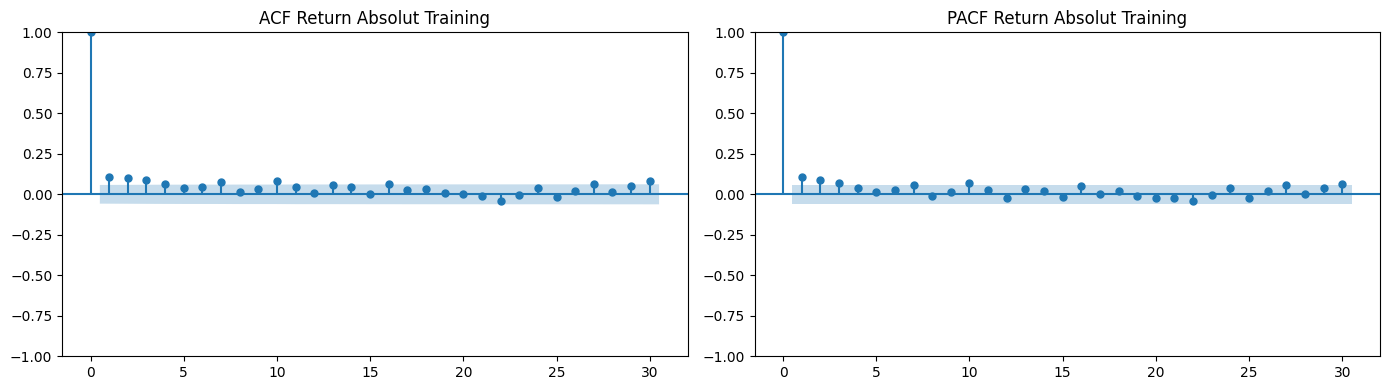

In [12]:
# ============================================
# 8C. ACF DAN PACF RETURN ABSOLUT
# ============================================

abs_return_train = r_train.abs()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(abs_return_train, lags=30, ax=axes[0])
axes[0].set_title("ACF Return Absolut Training")

plot_pacf(abs_return_train, lags=30, ax=axes[1], method="ywm")
axes[1].set_title("PACF Return Absolut Training")

plt.tight_layout()
plt.show()

In [13]:
# ============================================
# 8D. UJI LJUNG-BOX RETURN ABSOLUT
# ============================================

lb_abs_return = acorr_ljungbox(
    abs_return_train,
    lags=[5, 10, 20],
    return_df=True
)

print("Ljung-Box pada return absolut:")
display(lb_abs_return)

# ============================================
# 8E. UJI ARCH-LM
# ============================================

arch_lm = het_arch(r_train.dropna(), nlags=10)

print("ARCH-LM Statistic:", arch_lm[0])
print("ARCH-LM p-value  :", arch_lm[1])

if arch_lm[1] < 0.05:
    print("Terdapat bukti efek ARCH pada taraf 5%.")
else:
    print("Bukti efek ARCH belum cukup pada taraf 5%.")

Ljung-Box pada return absolut:


,lb_stat,lb_pvalue
5,39.900901,1.563683e-07
10,58.517612,6.905955e-09
20,74.224601,3.667180e-08


ARCH-LM Statistic: 28.300597955778336
ARCH-LM p-value  : 0.0016155790135670971
Terdapat bukti efek ARCH pada taraf 5%.


In [14]:
# ============================================
# 9. PEMILIHAN MODEL GARCH
# ============================================

# Skala return dalam persen
r_train_pct = 100 * r_train

hasil_garch = []
model_garch = {}

for p in range(1, 4):
    for q in range(1, 4):
        try:
            model = arch_model(
                r_train_pct,
                mean="Constant",
                vol="GARCH",
                p=p,
                q=q,
                dist="normal"
            )

            hasil = model.fit(disp="off")

            nama = f"GARCH({p},{q})"
            model_garch[nama] = hasil

            hasil_garch.append({
                "Model": nama,
                "p": p,
                "q": q,
                "AIC": hasil.aic,
                "BIC": hasil.bic,
                "LogLikelihood": hasil.loglikelihood,
                "Konvergen": hasil.convergence_flag == 0
            })

        except Exception as e:
            print(f"GARCH({p},{q}) gagal diestimasi: {e}")

tabel_garch = pd.DataFrame(hasil_garch)

# Hanya kandidat yang berhasil konvergen
tabel_garch = tabel_garch[
    tabel_garch["Konvergen"]
].sort_values("AIC").reset_index(drop=True)

print("Peringkat model GARCH berdasarkan AIC:")
display(tabel_garch)

if tabel_garch.empty:
    raise RuntimeError(
        "Tidak ada model GARCH yang berhasil konvergen."
    )

# Menetapkan model dengan AIC terkecil
nama_garch_terpilih = tabel_garch.loc[0, "Model"]
hasil_garch_terpilih = model_garch[nama_garch_terpilih]

print("Model GARCH terpilih:", nama_garch_terpilih)
print(hasil_garch_terpilih.summary())

Peringkat model GARCH berdasarkan AIC:


,Model,p,q,AIC,BIC,LogLikelihood,Konvergen
0,"GARCH(1,1)",1,1,619.229301,639.426320,-305.614650,True
1,"GARCH(1,3)",1,3,620.729667,651.025196,-304.364833,True
2,"GARCH(1,2)",1,2,621.228141,646.474415,-305.614070,True
3,"GARCH(2,1)",2,1,621.229301,646.475575,-305.614650,True
4,"GARCH(2,2)",2,2,623.228140,653.523669,-305.614070,True
5,"GARCH(3,1)",3,1,623.229301,653.524830,-305.614651,True
6,"GARCH(2,3)",2,3,625.073112,660.417896,-305.536556,True
7,"GARCH(3,2)",3,2,626.486541,661.831325,-306.243271,True
8,"GARCH(3,3)",3,3,627.073113,667.467151,-305.536556,True


Model GARCH terpilih: GARCH(1,1)
                     Constant Mean - GARCH Model Results                      
Dep. Variable:             Log_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -305.615
Distribution:                  Normal   AIC:                           619.229
Method:            Maximum Likelihood   BIC:                           639.426
                                        No. Observations:                 1152
Date:                Sun, Oct 25 2026   Df Residuals:                     1151
Time:                        03:45:03   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu             0.0193  8.

In [15]:
# ============================================
# 9.1 PARAMETER GARCH
# ============================================

print("Estimasi parameter:")
display(hasil_garch_terpilih.params)

print("\nStandard error:")
display(hasil_garch_terpilih.std_err)

print("\nP-value parameter:")
display(hasil_garch_terpilih.pvalues)

Estimasi parameter:


,params
mu,0.019261
omega,0.019789
alpha[1],0.095147
beta[1],0.709645



Standard error:


,std_err
mu,0.008791
omega,0.011182
alpha[1],0.039946
beta[1],0.127743



P-value parameter:


,pvalues
mu,2.845338e-02
omega,7.679151e-02
alpha[1],1.722293e-02
beta[1],2.772067e-08


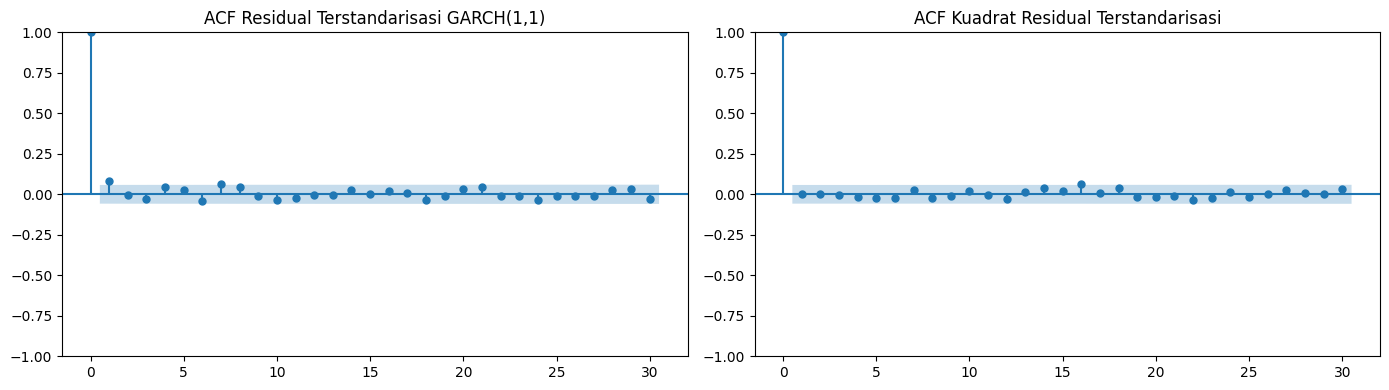

Ljung-Box residual terstandarisasi:


,lb_stat,lb_pvalue
5,12.374408,0.030003
10,23.221724,0.009957
20,28.536914,0.097286


Ljung-Box kuadrat residual terstandarisasi:


,lb_stat,lb_pvalue
5,1.059331,0.957640
10,3.925257,0.950656
20,14.737883,0.791204


ARCH-LM Statistic: 4.009414791590174
ARCH-LM p-value: 0.9469212651718499


In [16]:
# ============================================
# VALIDASI RESIDUAL MODEL GARCH TERPILIH
# ============================================

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import matplotlib.pyplot as plt

# Residual terstandarisasi
resid_std = (
    hasil_garch_terpilih.resid /
    hasil_garch_terpilih.conditional_volatility
).dropna()

# Visualisasi diagnostik
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(resid_std, lags=30, ax=axes[0])
axes[0].set_title("ACF Residual Terstandarisasi GARCH(1,1)")

plot_acf(resid_std**2, lags=30, ax=axes[1])
axes[1].set_title("ACF Kuadrat Residual Terstandarisasi")

plt.tight_layout()
plt.show()

# Ljung-Box residual
print("Ljung-Box residual terstandarisasi:")
display(
    acorr_ljungbox(
        resid_std,
        lags=[5, 10, 20],
        return_df=True
    )
)

# Ljung-Box kuadrat residual
print("Ljung-Box kuadrat residual terstandarisasi:")
display(
    acorr_ljungbox(
        resid_std**2,
        lags=[5, 10, 20],
        return_df=True
    )
)

# ARCH-LM residual
hasil_arch_resid = het_arch(resid_std, nlags=10)

print("ARCH-LM Statistic:", hasil_arch_resid[0])
print("ARCH-LM p-value:", hasil_arch_resid[1])

In [17]:
# ============================================
# EVALUASI SPESIFIKASI RATA-RATA GARCH
# ============================================

from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

# Data return training dalam persen
r_train_pct = 100 * r_train

# Model 1: GARCH(1,1), rata-rata konstan
model_const = arch_model(
    r_train_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

hasil_const = model_const.fit(disp="off")

# Model 2: AR(1)-GARCH(1,1)
model_ar1 = arch_model(
    r_train_pct,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

hasil_ar1 = model_ar1.fit(disp="off")

# Ringkasan perbandingan
perbandingan = pd.DataFrame({
    "Model": ["GARCH Constant", "AR(1)-GARCH(1,1)"],
    "AIC": [hasil_const.aic, hasil_ar1.aic],
    "BIC": [hasil_const.bic, hasil_ar1.bic],
    "LogLikelihood": [
        hasil_const.loglikelihood,
        hasil_ar1.loglikelihood
    ],
    "Konvergen": [
        hasil_const.convergence_flag == 0,
        hasil_ar1.convergence_flag == 0
    ]
})

display(perbandingan)

print("Ringkasan AR(1)-GARCH(1,1):")
print(hasil_ar1.summary())

,Model,AIC,BIC,LogLikelihood,Konvergen
0,GARCH Constant,619.229301,639.426320,-305.61465,True
1,"AR(1)-GARCH(1,1)",581.405901,606.647833,-285.70295,True


Ringkasan AR(1)-GARCH(1,1):
                           AR - GARCH Model Results                           
Dep. Variable:             Log_Return   R-squared:                       0.006
Mean Model:                        AR   Adj. R-squared:                  0.005
Vol Model:                      GARCH   Log-Likelihood:               -285.703
Distribution:                  Normal   AIC:                           581.406
Method:            Maximum Likelihood   BIC:                           606.648
                                        No. Observations:                 1151
Date:                Sun, Oct 25 2026   Df Residuals:                     1149
Time:                        03:53:22   Df Model:                            2
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
--------------------------------------------------------------------------------
Const             

In [18]:
# ============================================
# DIAGNOSTIK AR(1)-GARCH(1,1)
# ============================================

resid_ar1_std = (
    hasil_ar1.resid / hasil_ar1.conditional_volatility
).dropna()

print("Ljung-Box residual:")
display(
    acorr_ljungbox(
        resid_ar1_std,
        lags=[5, 10, 20],
        return_df=True
    )
)

print("Ljung-Box kuadrat residual:")
display(
    acorr_ljungbox(
        resid_ar1_std**2,
        lags=[5, 10, 20],
        return_df=True
    )
)

hasil_arch_ar1 = het_arch(resid_ar1_std, nlags=10)

print("ARCH-LM Statistic:", hasil_arch_ar1[0])
print("ARCH-LM p-value:", hasil_arch_ar1[1])

Ljung-Box residual:


,lb_stat,lb_pvalue
5,6.679395,0.245597
10,19.035836,0.039810
20,23.643635,0.258306


Ljung-Box kuadrat residual:


,lb_stat,lb_pvalue
5,7.609238,0.179127
10,11.569743,0.314883
20,16.711627,0.671612


ARCH-LM Statistic: 11.655928016503907
ARCH-LM p-value: 0.3087436685406134


In [19]:
# ============================================
# ESTIMASI AR(2)-GARCH(1,1)
# ============================================

from arch import arch_model
from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_arch
)

model_ar2 = arch_model(
    r_train_pct,
    mean="AR",
    lags=2,
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

hasil_ar2 = model_ar2.fit(disp="off")

print(hasil_ar2.summary())

# Membandingkan AIC dan BIC
tabel_perbandingan = pd.DataFrame({
    "Model": [
        "GARCH(1,1) Constant",
        "AR(1)-GARCH(1,1)",
        "AR(2)-GARCH(1,1)"
    ],
    "AIC": [
        hasil_const.aic,
        hasil_ar1.aic,
        hasil_ar2.aic
    ],
    "BIC": [
        hasil_const.bic,
        hasil_ar1.bic,
        hasil_ar2.bic
    ],
    "Konvergen": [
        hasil_const.convergence_flag == 0,
        hasil_ar1.convergence_flag == 0,
        hasil_ar2.convergence_flag == 0
    ]
})

display(tabel_perbandingan)

                           AR - GARCH Model Results                           
Dep. Variable:             Log_Return   R-squared:                       0.007
Mean Model:                        AR   Adj. R-squared:                  0.006
Vol Model:                      GARCH   Log-Likelihood:               -285.449
Distribution:                  Normal   AIC:                           582.898
Method:            Maximum Likelihood   BIC:                           613.183
                                        No. Observations:                 1150
Date:                Sun, Oct 25 2026   Df Residuals:                     1147
Time:                        03:55:29   Df Model:                            3
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
--------------------------------------------------------------------------------
Const             0.0131  8.920e-03      1.468

,Model,AIC,BIC,Konvergen
0,"GARCH(1,1) Constant",619.229301,639.426320,True
1,"AR(1)-GARCH(1,1)",581.405901,606.647833,True
2,"AR(2)-GARCH(1,1)",582.898343,613.183447,True


In [20]:
# ============================================
# DIAGNOSTIK AR(2)-GARCH(1,1)
# ============================================

resid_ar2_std = (
    hasil_ar2.resid /
    hasil_ar2.conditional_volatility
).dropna()

print("Ljung-Box residual terstandarisasi:")
display(
    acorr_ljungbox(
        resid_ar2_std,
        lags=[5, 10, 20],
        return_df=True
    )
)

print("Ljung-Box kuadrat residual:")
display(
    acorr_ljungbox(
        resid_ar2_std**2,
        lags=[5, 10, 20],
        return_df=True
    )
)

hasil_arch_ar2 = het_arch(
    resid_ar2_std,
    nlags=10
)

print("ARCH-LM Statistic:", hasil_arch_ar2[0])
print("ARCH-LM p-value:", hasil_arch_ar2[1])

Ljung-Box residual terstandarisasi:


,lb_stat,lb_pvalue
5,5.831437,0.322968
10,17.985859,0.055203
20,22.447999,0.316704


Ljung-Box kuadrat residual:


,lb_stat,lb_pvalue
5,7.470304,0.187946
10,11.441787,0.324150
20,16.565158,0.681002


ARCH-LM Statistic: 11.614015204159019
ARCH-LM p-value: 0.31171906435183794


In [21]:
# ============================================
# PEMERIKSAAN PARAMETER AR(2)-GARCH(1,1)
# ============================================

print(hasil_ar2.summary())

print("\nKoefisien model:")
display(hasil_ar2.params)

print("\nP-value parameter:")
display(hasil_ar2.pvalues)

                           AR - GARCH Model Results                           
Dep. Variable:             Log_Return   R-squared:                       0.007
Mean Model:                        AR   Adj. R-squared:                  0.006
Vol Model:                      GARCH   Log-Likelihood:               -285.449
Distribution:                  Normal   AIC:                           582.898
Method:            Maximum Likelihood   BIC:                           613.183
                                        No. Observations:                 1150
Date:                Sun, Oct 25 2026   Df Residuals:                     1147
Time:                        03:55:29   Df Model:                            3
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
--------------------------------------------------------------------------------
Const             0.0131  8.920e-03      1.468

,params
Const,0.013091
Log_Return[1],0.088459
Log_Return[2],-0.012622
omega,0.000548
alpha[1],0.023057
beta[1],0.971901



P-value parameter:


,pvalues
Const,0.142184
Log_Return[1],0.007000
Log_Return[2],0.684516
omega,0.320386
alpha[1],0.005822
beta[1],0.000000


In [22]:
# ============================================
# TAHAP 10.1: PERSIAPAN DATA LSTM
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproduksibilitas
np.random.seed(123)
tf.random.set_seed(123)

# Panjang urutan input
LOOKBACK = 10

# Menggunakan log return yang sudah dibagi sebelumnya
# Skala return dikalikan 100 agar lebih nyaman untuk estimasi numerik
train_values = (r_train.to_numpy() * 100).reshape(-1, 1)
test_values = (r_test.to_numpy() * 100).reshape(-1, 1)

# Scaling hanya berdasarkan training
scaler_lstm = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler_lstm.fit_transform(train_values)

print("Jumlah data training:", len(train_values))
print("Jumlah data testing :", len(test_values))
print("Bentuk data training setelah scaling:", train_scaled.shape)

Jumlah data training: 1152
Jumlah data testing : 289
Bentuk data training setelah scaling: (1152, 1)


In [23]:
# ============================================
# TAHAP 10.2: MEMBENTUK SEQUENCES
# ============================================

def buat_sequences(data_scaled, lookback):
    X, y = [], []

    for i in range(lookback, len(data_scaled)):
        X.append(data_scaled[i - lookback:i, 0])
        y.append(data_scaled[i, 0])

    X = np.array(X)
    y = np.array(y)

    return X.reshape(-1, lookback, 1), y


X_train_lstm, y_train_lstm = buat_sequences(
    train_scaled,
    LOOKBACK
)

print("Bentuk X training:", X_train_lstm.shape)
print("Bentuk y training:", y_train_lstm.shape)

Bentuk X training: (1142, 10, 1)
Bentuk y training: (1142,)


In [24]:
# ============================================
# TAHAP 10.3: MEMBANGUN MODEL LSTM
# ============================================

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(123)

model_lstm = Sequential([
    LSTM(
        units=50,
        input_shape=(LOOKBACK, 1)
    ),
    Dropout(0.2),
    Dense(1)
])

model_lstm.compile(
    optimizer="adam",
    loss="mse"
)

model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# ============================================
# TAHAP 10.4: TRAINING MODEL LSTM
# ============================================

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_lstm = model_lstm.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.0663 - val_loss: 0.0110
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0092 - val_loss: 0.0080
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0092 - val_loss: 0.0080
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0084 - val_loss: 0.0079
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0077 - val_loss: 0.0080
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0079 - val_loss: 0.0079
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0083 - val_loss: 0.0079
Epoch 8/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0081 - val_loss: 0.0079
Epoch 9/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0079 - val_loss: 0.0079
Epoch 10/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0079 - val_loss: 0.0079
Epoch 11/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0074 - val_loss: 0.0079
Epoch 12/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss

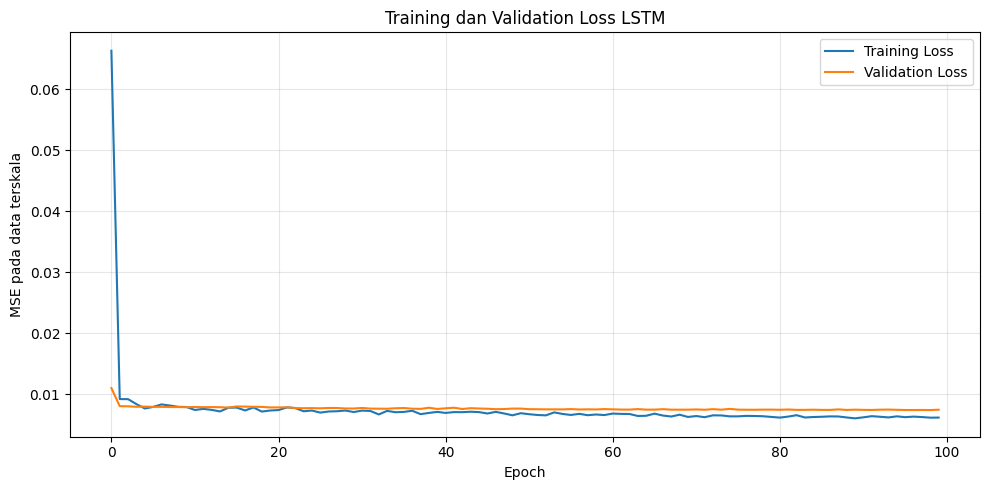

Epoch terbaik: 99
Validation loss minimum: 0.0074073076248168945


In [27]:
# ============================================
# GRAFIK LOSS LSTM
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(
    history_lstm.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training dan Validation Loss LSTM")
plt.xlabel("Epoch")
plt.ylabel("MSE pada data terskala")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Epoch terbaik:",
      np.argmin(history_lstm.history["val_loss"]) + 1)

print("Validation loss minimum:",
      min(history_lstm.history["val_loss"]))

In [28]:
# ============================================
# TAHAP 10.5: PREDIKSI LSTM TESTING
# ============================================

# Jendela awal berasal dari akhir data training
window = train_scaled[-LOOKBACK:, 0].tolist()

prediksi_scaled = []

for i in range(len(test_values)):

    X_input = np.array(
        window[-LOOKBACK:]
    ).reshape(1, LOOKBACK, 1)

    pred = model_lstm.predict(
        X_input,
        verbose=0
    )[0, 0]

    prediksi_scaled.append(pred)

    # Gunakan prediksi untuk langkah selanjutnya
    window.append(pred)

# Kembalikan ke skala return persen
prediksi_lstm_pct = scaler_lstm.inverse_transform(
    np.array(prediksi_scaled).reshape(-1, 1)
).flatten()

# Kembalikan ke skala log return semula
prediksi_lstm = prediksi_lstm_pct / 100

print("Jumlah prediksi LSTM:", len(prediksi_lstm))
print("Jumlah aktual testing:", len(r_test))

Jumlah prediksi LSTM: 289
Jumlah aktual testing: 289


In [29]:
# ============================================
# TAHAP 10.6: TABEL HASIL PREDIKSI
# ============================================

hasil_lstm = pd.DataFrame({
    "Tanggal": test["Tanggal"].to_numpy(),
    "Aktual_Log_Return": r_test.to_numpy(),
    "Prediksi_LSTM": prediksi_lstm
})

display(hasil_lstm.head(10))

,Tanggal,Aktual_Log_Return,Prediksi_LSTM
0,2025-07-24,-0.000307,0.000038
1,2025-07-25,0.001840,0.000036
2,2025-07-28,0.001531,0.000018
3,2025-07-29,0.003330,-0.000011
4,2025-07-30,-0.000275,-0.000025
5,2025-07-31,0.003958,-0.000034
6,2025-08-01,0.002125,-0.000056
7,2025-08-04,-0.006083,-0.000038
8,2025-08-05,-0.000610,-0.000045
9,2025-08-06,-0.001222,-0.000042


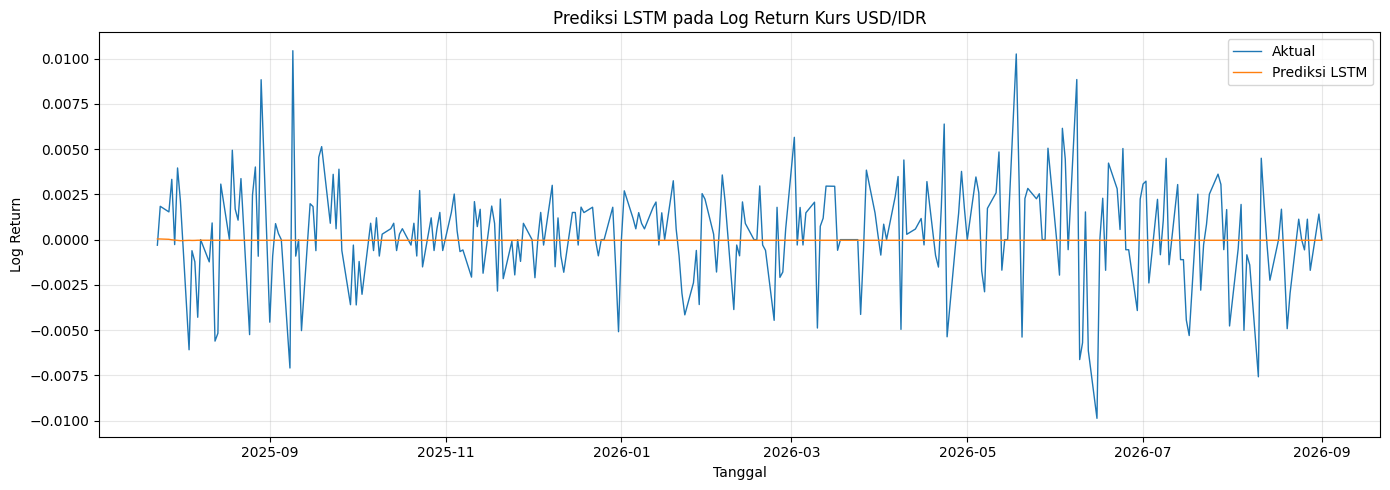

In [30]:
# ============================================
# GRAFIK AKTUAL VS PREDIKSI LSTM
# ============================================

plt.figure(figsize=(14, 5))

plt.plot(
    hasil_lstm["Tanggal"],
    hasil_lstm["Aktual_Log_Return"],
    label="Aktual",
    linewidth=1
)

plt.plot(
    hasil_lstm["Tanggal"],
    hasil_lstm["Prediksi_LSTM"],
    label="Prediksi LSTM",
    linewidth=1
)

plt.title("Prediksi LSTM pada Log Return Kurs USD/IDR")
plt.xlabel("Tanggal")
plt.ylabel("Log Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
# ============================================
# EVALUASI LSTM MANDIRI PADA DATA TESTING
# ============================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error

aktual_lstm = r_test.to_numpy()
pred_lstm = np.asarray(prediksi_lstm)

mse_lstm = mean_squared_error(aktual_lstm, pred_lstm)
rmse_lstm = np.sqrt(mse_lstm)
mae_lstm = mean_absolute_error(aktual_lstm, pred_lstm)

# MAPE untuk log return perlu hati-hati karena
# nilai aktual dapat mendekati nol.
mask = np.abs(aktual_lstm) > 1e-10

mape_lstm = (
    np.mean(
        np.abs(
            (aktual_lstm[mask] - pred_lstm[mask])
            / aktual_lstm[mask]
        )
    ) * 100
    if mask.any()
    else np.nan
)

evaluasi_lstm = pd.DataFrame({
    "Metrik": ["MSE", "RMSE", "MAE", "MAPE (%)"],
    "LSTM": [mse_lstm, rmse_lstm, mae_lstm, mape_lstm]
})

display(evaluasi_lstm)

,Metrik,LSTM
0,MSE,0.000008
1,RMSE,0.002830
2,MAE,0.002065
3,MAPE (%),99.636051


Jumlah residual training: 1151

Ringkasan residual:


,resid
count,1151.000000
mean,-0.000419
std,0.318463
min,-1.312715
25%,-0.146818
50%,-0.005890
75%,0.173758
max,1.812246


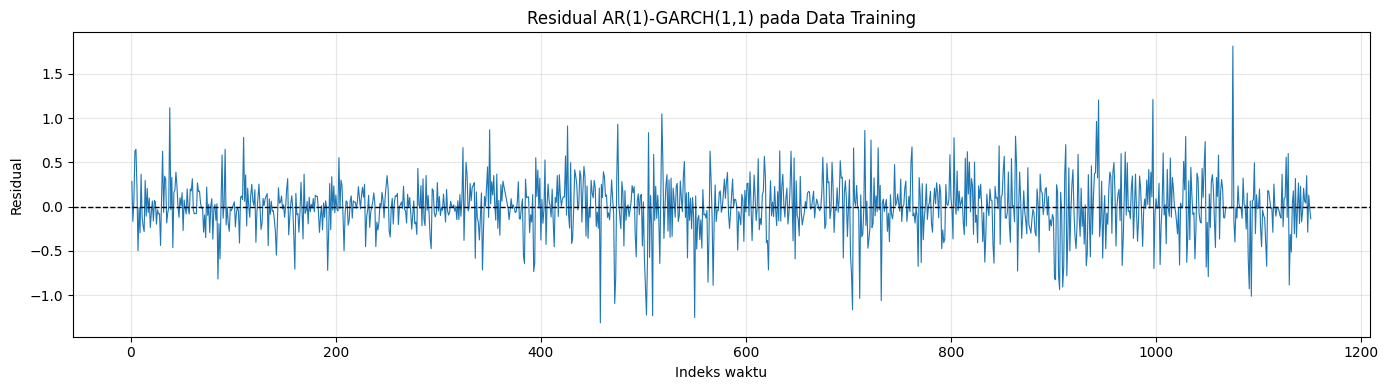

In [32]:
# ============================================
# TAHAP 11.1: RESIDUAL AR(1)-GARCH(1,1)
# ============================================

# Model AR(1)-GARCH(1,1) yang sudah dipilih
model_garch_final = hasil_ar1

# Residual hasil estimasi training
residual_ar1_garch = model_garch_final.resid.dropna()

# Pastikan jumlah observasi tersedia
print("Jumlah residual training:", len(residual_ar1_garch))

print("\nRingkasan residual:")
display(residual_ar1_garch.describe())

# Visualisasi residual
plt.figure(figsize=(14, 4))

plt.plot(
    residual_ar1_garch.index,
    residual_ar1_garch.values,
    linewidth=0.8
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Residual AR(1)-GARCH(1,1) pada Data Training")
plt.xlabel("Indeks waktu")
plt.ylabel("Residual")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# ============================================
# TAHAP 11.2: SCALING DAN SEQUENCES RESIDUAL
# ============================================

from sklearn.preprocessing import MinMaxScaler
import numpy as np

LOOKBACK = 10

# Residual AR(1)-GARCH(1,1), dalam skala persen
resid_values = residual_ar1_garch.to_numpy().reshape(-1, 1)

# Scaling residual training
scaler_resid = MinMaxScaler(feature_range=(0, 1))
resid_scaled = scaler_resid.fit_transform(resid_values)

# Membentuk sequences
X_train_hybrid, y_train_hybrid = buat_sequences(
    resid_scaled,
    LOOKBACK
)

print("Jumlah residual:", len(resid_values))
print("Bentuk X hybrid:", X_train_hybrid.shape)
print("Bentuk y hybrid:", y_train_hybrid.shape)

Jumlah residual: 1151
Bentuk X hybrid: (1141, 10, 1)
Bentuk y hybrid: (1141,)


In [34]:
# ============================================
# TAHAP 11.3: MODEL LSTM RESIDUAL
# ============================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(123)

model_hybrid = Sequential([
    LSTM(
        units=50,
        input_shape=(LOOKBACK, 1)
    ),
    Dropout(0.2),
    Dense(1)
])

model_hybrid.compile(
    optimizer="adam",
    loss="mse"
)

early_stop_hybrid = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_hybrid = model_hybrid.fit(
    X_train_hybrid,
    y_train_hybrid,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop_hybrid],
    verbose=1
)

Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0421 - val_loss: 0.0158
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0125 - val_loss: 0.0140
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0119 - val_loss: 0.0139
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0116 - val_loss: 0.0139
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0114 - val_loss: 0.0139
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0112 - val_loss: 0.0138
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0115 - val_loss: 0.0138
Epoch 8/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0117 - val_loss: 0.0138
Epoch 9/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0115 - val_loss: 0.0137
Epoch 10/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0108 - val_loss: 0.0137
Epoch 11/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0114 - val_loss: 0.0137
Epoch 12/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - los

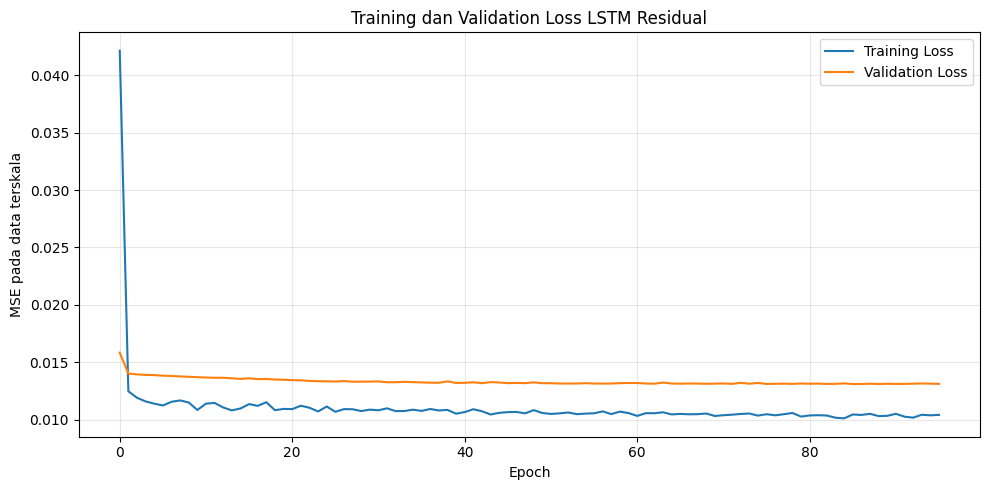

In [35]:
# ============================================
# GRAFIK LOSS LSTM RESIDUAL
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_hybrid.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_hybrid.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training dan Validation Loss LSTM Residual")
plt.xlabel("Epoch")
plt.ylabel("MSE pada data terskala")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
# ============================================
# TAHAP 11.4A: PREDIKSI AR(1)-GARCH(1,1)
# ============================================

# Jumlah periode testing
horizon = len(r_test)

# Forecast dari model AR(1)-GARCH(1,1)
forecast_garch = hasil_ar1.forecast(
    horizon=horizon,
    method="analytic",
    reindex=False
)

# Prediksi rata-rata return dalam skala persen
prediksi_garch_pct = (
    forecast_garch.mean.iloc[-1].to_numpy()
)

print("Jumlah prediksi GARCH:", len(prediksi_garch_pct))
print("\nLima prediksi GARCH pertama (persen):")
print(prediksi_garch_pct[:5])

Jumlah prediksi GARCH: 289

Lima prediksi GARCH pertama (persen):
[0.00342053 0.01360823 0.01443117 0.01449764 0.01450301]


In [37]:
# ============================================
# TAHAP 11.5: PREDIKSI RESIDUAL DENGAN LSTM
# ============================================

# Residual training sudah diskalakan pada Tahap 11.2
window_resid = resid_scaled[-LOOKBACK:, 0].tolist()

prediksi_resid_scaled = []

for i in range(len(r_test)):

    X_input = np.array(
        window_resid[-LOOKBACK:]
    ).reshape(1, LOOKBACK, 1)

    pred_scaled = model_hybrid.predict(
        X_input,
        verbose=0
    )[0, 0]

    prediksi_resid_scaled.append(pred_scaled)

    # Prediksi residual digunakan untuk langkah berikutnya
    window_resid.append(pred_scaled)

# Kembalikan ke skala residual GARCH (persen)
prediksi_resid_pct = scaler_resid.inverse_transform(
    np.array(prediksi_resid_scaled).reshape(-1, 1)
).flatten()

print("Jumlah prediksi residual:", len(prediksi_resid_pct))
print("\nLima prediksi residual pertama (persen):")
print(prediksi_resid_pct[:5])

Jumlah prediksi residual: 289

Lima prediksi residual pertama (persen):
[-0.00328317 -0.00410236 -0.0062643  -0.00983402 -0.01129766]


In [38]:
# ============================================
# TAHAP 11.6: PREDIKSI HYBRID
# ============================================

# Semua komponen masih dalam skala return persen
prediksi_hybrid_pct = (
    prediksi_garch_pct + prediksi_resid_pct
)

# Konversi kembali ke skala log return asli
prediksi_garch = prediksi_garch_pct / 100
prediksi_resid = prediksi_resid_pct / 100
prediksi_hybrid = prediksi_hybrid_pct / 100

# Data aktual testing dalam skala log return asli
aktual_return = r_test.to_numpy()

# Tabel hasil prediksi
hasil_hybrid = pd.DataFrame({
    "Tanggal": test["Tanggal"].to_numpy(),
    "Aktual_Log_Return": aktual_return,
    "Prediksi_GARCH": prediksi_garch,
    "Prediksi_Residual_LSTM": prediksi_resid,
    "Prediksi_Hybrid": prediksi_hybrid
})

print("Lima hasil prediksi hybrid pertama:")
display(hasil_hybrid.head())

print("\nJumlah observasi:")
print("Aktual :", len(aktual_return))
print("GARCH  :", len(prediksi_garch))
print("Hybrid :", len(prediksi_hybrid))

Lima hasil prediksi hybrid pertama:


,Tanggal,Aktual_Log_Return,Prediksi_GARCH,Prediksi_Residual_LSTM,Prediksi_Hybrid
0,2025-07-24,-0.000307,0.000034,-0.000033,0.000001
1,2025-07-25,0.001840,0.000136,-0.000041,0.000095
2,2025-07-28,0.001531,0.000144,-0.000063,0.000082
3,2025-07-29,0.003330,0.000145,-0.000098,0.000047
4,2025-07-30,-0.000275,0.000145,-0.000113,0.000032



Jumlah observasi:
Aktual : 289
GARCH  : 289
Hybrid : 289


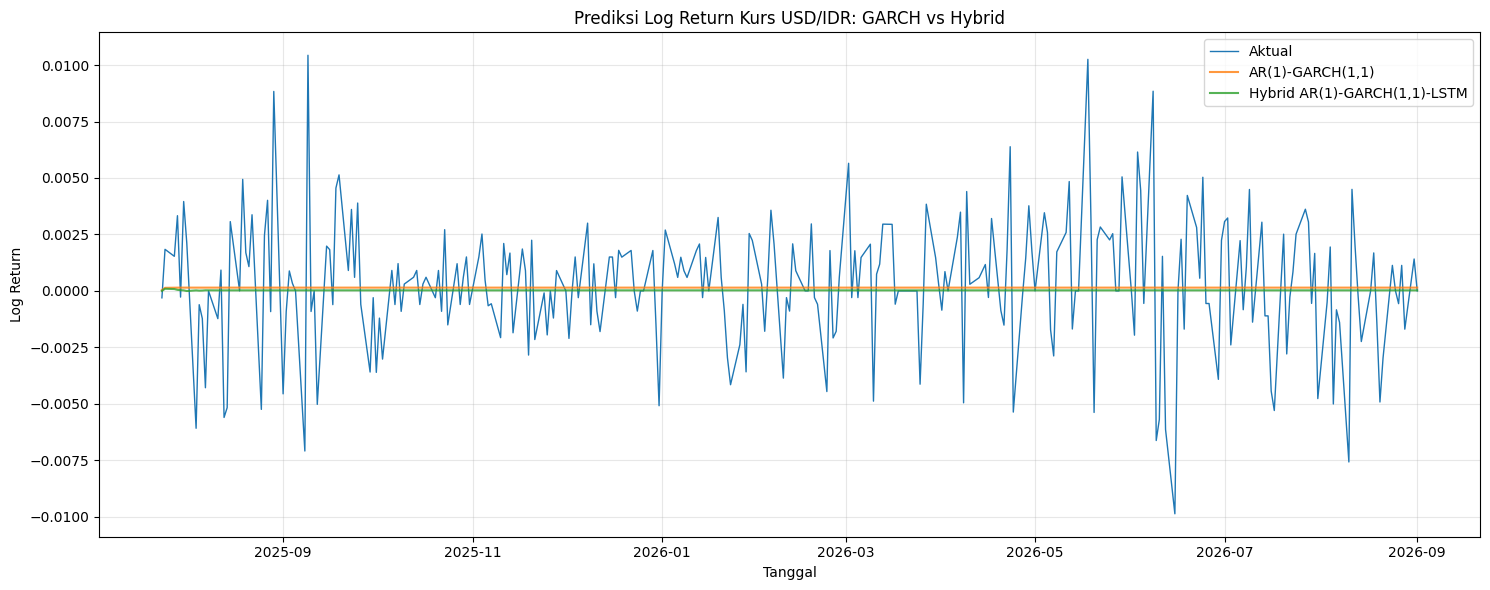

In [39]:
# ============================================
# TAHAP 11.7: GRAFIK PREDIKSI HYBRID
# ============================================

plt.figure(figsize=(15, 6))

plt.plot(
    hasil_hybrid["Tanggal"],
    hasil_hybrid["Aktual_Log_Return"],
    label="Aktual",
    linewidth=1
)

plt.plot(
    hasil_hybrid["Tanggal"],
    hasil_hybrid["Prediksi_GARCH"],
    label="AR(1)-GARCH(1,1)",
    alpha=0.8
)

plt.plot(
    hasil_hybrid["Tanggal"],
    hasil_hybrid["Prediksi_Hybrid"],
    label="Hybrid AR(1)-GARCH(1,1)-LSTM",
    alpha=0.8
)

plt.title("Prediksi Log Return Kurs USD/IDR: GARCH vs Hybrid")
plt.xlabel("Tanggal")
plt.ylabel("Log Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
# ============================================
# PEMERIKSAAN VARIASI PREDIKSI
# ============================================

ringkasan_prediksi = pd.DataFrame({
    "Aktual": aktual_return,
    "GARCH": prediksi_garch,
    "Residual_LSTM": prediksi_resid,
    "Hybrid": prediksi_hybrid
})

print("Ringkasan prediksi:")
display(ringkasan_prediksi.describe().T)

print("\nStandar deviasi:")
print(ringkasan_prediksi.std())

print("\nRasio standar deviasi prediksi terhadap aktual:")

std_aktual = np.std(aktual_return, ddof=1)

for kolom in ["GARCH", "Residual_LSTM", "Hybrid"]:
    rasio = (
        ringkasan_prediksi[kolom].std() / std_aktual
    )
    print(f"{kolom}: {rasio:.4f}")

Ringkasan prediksi:


,count,mean,std,min,25%,50%,75%,max
Aktual,289.0,0.000290,0.002817,-0.009869,-0.000899,0.000000,0.001840,0.010434
GARCH,289.0,0.000145,0.000007,0.000034,0.000145,0.000145,0.000145,0.000145
Residual_LSTM,289.0,-0.000120,0.000008,-0.000150,-0.000121,-0.000121,-0.000121,-0.000033
Hybrid,289.0,0.000024,0.000006,-0.000005,0.000024,0.000024,0.000024,0.000095



Standar deviasi:
Aktual           0.002817
GARCH            0.000007
Residual_LSTM    0.000008
Hybrid           0.000006
dtype: float64

Rasio standar deviasi prediksi terhadap aktual:
GARCH: 0.0023
Residual_LSTM: 0.0029
Hybrid: 0.0021


In [41]:
# ============================================
# PEMERIKSAAN PARAMETER AR(1)-GARCH(1,1)
# ============================================

print("Parameter model:")
display(hasil_ar1.params)

print("\nKoefisien AR(1):",
      hasil_ar1.params.get("Log_Return[1]"))

print("\nLima prediksi GARCH pertama:")
print(prediksi_garch[:5])

print("\nLima prediksi residual LSTM pertama:")
print(prediksi_resid[:5])

print("\nLima prediksi hybrid pertama:")
print(prediksi_hybrid[:5])

Parameter model:


,params
Const,0.013332
Log_Return[1],0.080778
omega,0.000548
alpha[1],0.022990
beta[1],0.971969



Koefisien AR(1): 0.0807778260405571

Lima prediksi GARCH pertama:
[3.42053478e-05 1.36082291e-04 1.44311689e-04 1.44976442e-04
 1.45030139e-04]

Lima prediksi residual LSTM pertama:
[-3.2831744e-05 -4.1023559e-05 -6.2643012e-05 -9.8340155e-05
 -1.1297664e-04]

Lima prediksi hybrid pertama:
[1.37360301e-06 9.50587328e-05 8.16686786e-05 4.66362843e-05
 3.20535022e-05]


In [42]:
# ============================================
# PEMERIKSAAN PREDIKSI GARCH
# ============================================

forecast_check = hasil_ar1.forecast(
    horizon=len(r_test),
    method="analytic",
    reindex=False
)

prediksi_garch_check = (
    forecast_check.mean.iloc[-1].to_numpy() / 100
)

print("Lima prediksi GARCH hasil pemeriksaan:")
print(prediksi_garch_check[:5])

print("\nLima prediksi GARCH sebelumnya:")
print(prediksi_garch[:5])

print("\nApakah kedua hasil sama?")
print(
    np.allclose(
        prediksi_garch_check,
        prediksi_garch
    )
)

Lima prediksi GARCH hasil pemeriksaan:
[3.42053478e-05 1.36082291e-04 1.44311689e-04 1.44976442e-04
 1.45030139e-04]

Lima prediksi GARCH sebelumnya:
[3.42053478e-05 1.36082291e-04 1.44311689e-04 1.44976442e-04
 1.45030139e-04]

Apakah kedua hasil sama?
True


In [43]:
# ============================================
# TAHAP 12: EVALUASI TIGA MODEL
# ============================================

from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

aktual = r_test.to_numpy()

prediksi_semua = {
    "AR(1)-GARCH(1,1)": np.asarray(prediksi_garch),
    "LSTM": np.asarray(prediksi_lstm),
    "Hybrid AR(1)-GARCH(1,1)-LSTM": np.asarray(prediksi_hybrid)
}

hasil_evaluasi = []

for nama, prediksi in prediksi_semua.items():
    mse = mean_squared_error(aktual, prediksi)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(aktual, prediksi)

    hasil_evaluasi.append({
        "Model": nama,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae
    })

tabel_evaluasi = pd.DataFrame(hasil_evaluasi)

display(tabel_evaluasi.round(8))

,Model,MSE,RMSE,MAE
0,"AR(1)-GARCH(1,1)",0.000008,0.002815,0.002058
1,LSTM,0.000008,0.002830,0.002065
2,"Hybrid AR(1)-GARCH(1,1)-LSTM",0.000008,0.002824,0.002057


In [44]:
# ============================================
# EVALUASI DENGAN PRESISI PENUH
# ============================================

pd.set_option("display.precision", 12)

display(
    tabel_evaluasi.sort_values("RMSE")
                  .reset_index(drop=True)
)

,Model,MSE,RMSE,MAE
0,"AR(1)-GARCH(1,1)",0.000007926691,0.002815438054,0.002058072416
1,"Hybrid AR(1)-GARCH(1,1)-LSTM",0.000007975025,0.002824008687,0.002057465751
2,LSTM,0.000008010192,0.002830228224,0.002064974420


In [45]:
# ============================================
# PERUBAHAN ERROR HYBRID TERHADAP GARCH
# ============================================

eval_index = tabel_evaluasi.set_index("Model")

nama_garch = "AR(1)-GARCH(1,1)"
nama_hybrid = "Hybrid AR(1)-GARCH(1,1)-LSTM"

for metrik in ["MSE", "RMSE", "MAE"]:
    nilai_garch = eval_index.loc[nama_garch, metrik]
    nilai_hybrid = eval_index.loc[nama_hybrid, metrik]

    perubahan = (
        (nilai_garch - nilai_hybrid) / nilai_garch
    ) * 100

    print(f"{metrik}: {perubahan:.6f}%")

MSE: -0.609758%
RMSE: -0.304416%
MAE: 0.029477%


In [46]:
# ============================================
# TAHAP 13.1: REKONSTRUKSI HARGA KURS
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Harga kurs terakhir pada training
harga_awal = train["Kurs"].iloc[-1]

# Return aktual dan prediksi dalam skala log return asli
return_aktual = r_test.to_numpy()

# Rekonstruksi harga secara rekursif
def rekonstruksi_harga(harga_awal, prediksi_return):
    prediksi_return = np.asarray(prediksi_return)
    return harga_awal * np.exp(np.cumsum(prediksi_return))

# Harga aktual dan prediksi
harga_aktual = test["Kurs"].to_numpy()

harga_garch = rekonstruksi_harga(
    harga_awal, prediksi_garch
)

harga_lstm = rekonstruksi_harga(
    harga_awal, prediksi_lstm
)

harga_hybrid = rekonstruksi_harga(
    harga_awal, prediksi_hybrid
)

# Tabel hasil
hasil_harga = pd.DataFrame({
    "Tanggal": test["Tanggal"].to_numpy(),
    "Harga_Aktual": harga_aktual,
    "Harga_GARCH": harga_garch,
    "Harga_LSTM": harga_lstm,
    "Harga_Hybrid": harga_hybrid
})

print("Harga terakhir pada training:", harga_awal)
display(hasil_harga.head(10))

Harga terakhir pada training: 16290.0


,Tanggal,Harga_Aktual,Harga_GARCH,Harga_LSTM,Harga_Hybrid
0,2025-07-24,16285.0,16290.557214644899,16290.615588426590,16290.022376008381
1,2025-07-25,16315.0,16292.774221833590,16291.200106143951,16291.570958494834
2,2025-07-28,16340.0,16295.125629260436,16291.493335962296,16292.901523899804
3,2025-07-29,16394.5,16297.488209845949,16291.316621303558,16293.661382004973
4,2025-07-30,16390.0,16299.852008232716,16290.910760164261,16294.183659286786
5,2025-07-31,16455.0,16302.216220178034,16290.359255075455,16294.567381714478
6,2025-08-01,16490.0,16304.580780753229,16289.445582032204,16294.483017081429
7,2025-08-04,16390.0,16306.945684758457,16288.829993605614,16294.848299298266
8,2025-08-05,16380.0,16309.310931819358,16288.103715777397,16295.036821760292
9,2025-08-06,16360.0,16311.676521951420,16287.414334416389,16295.285685977558


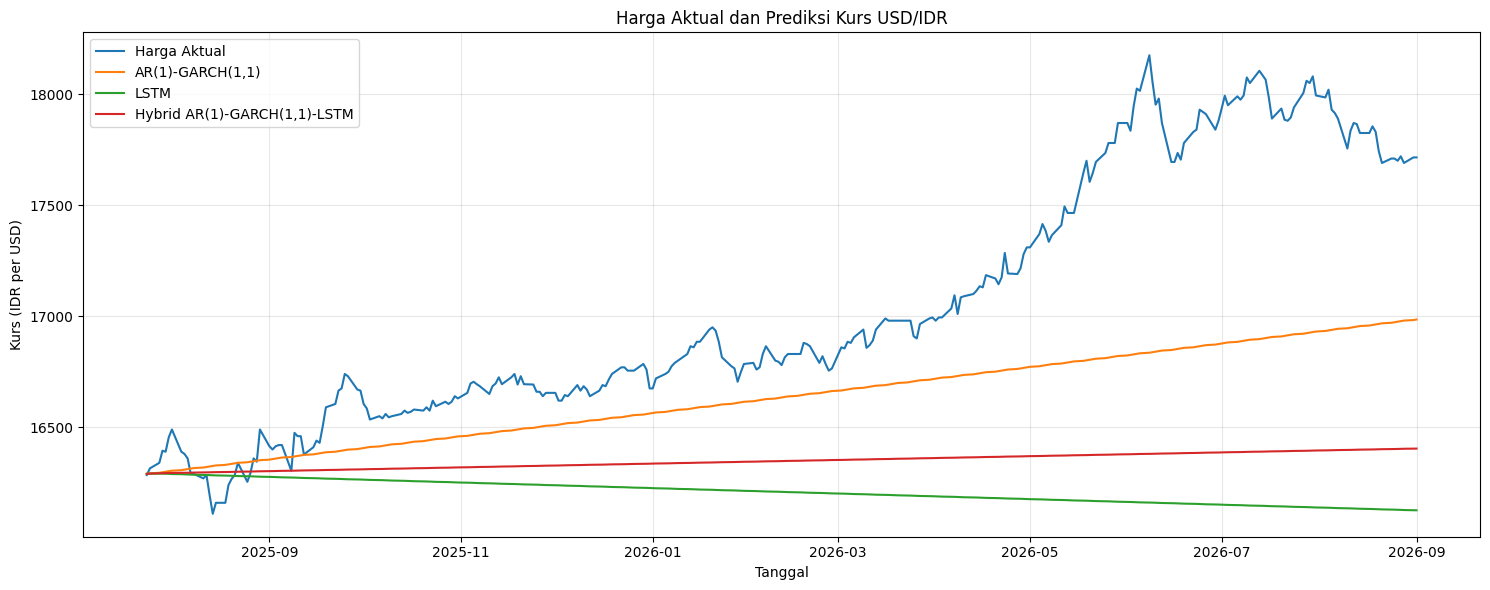

In [47]:
# ============================================
# TAHAP 13.2: VISUALISASI HARGA KURS
# ============================================

plt.figure(figsize=(15, 6))

plt.plot(
    hasil_harga["Tanggal"],
    hasil_harga["Harga_Aktual"],
    label="Harga Aktual",
    linewidth=1.5
)

plt.plot(
    hasil_harga["Tanggal"],
    hasil_harga["Harga_GARCH"],
    label="AR(1)-GARCH(1,1)"
)

plt.plot(
    hasil_harga["Tanggal"],
    hasil_harga["Harga_LSTM"],
    label="LSTM"
)

plt.plot(
    hasil_harga["Tanggal"],
    hasil_harga["Harga_Hybrid"],
    label="Hybrid AR(1)-GARCH(1,1)-LSTM"
)

plt.title("Harga Aktual dan Prediksi Kurs USD/IDR")
plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [48]:
# ============================================
# TAHAP 13.3: EVALUASI HARGA KURS
# ============================================

from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluasi_harga(aktual, prediksi):
    aktual = np.asarray(aktual)
    prediksi = np.asarray(prediksi)

    mse = mean_squared_error(aktual, prediksi)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(aktual, prediksi)

    # MAPE untuk harga positif
    mask = np.abs(aktual) > 1e-10
    mape = np.mean(
        np.abs(
            (aktual[mask] - prediksi[mask]) / aktual[mask]
        )
    ) * 100

    return {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape
    }

evaluasi_harga_kurs = pd.DataFrame({
    "AR(1)-GARCH(1,1)": evaluasi_harga(
        harga_aktual, harga_garch
    ),
    "LSTM": evaluasi_harga(
        harga_aktual, harga_lstm
    ),
    "Hybrid": evaluasi_harga(
        harga_aktual, harga_hybrid
    )
}).T

display(evaluasi_harga_kurs)

,MSE,RMSE,MAE,MAPE (%)
"AR(1)-GARCH(1,1)",3.104116140116e+05,557.145953957816,419.018677861472,2.393336895437
LSTM,1.066129903275e+06,1032.535666829645,840.757762380950,4.824125587061
Hybrid,7.673692411172e+05,875.996142181674,703.350878394267,4.031966082755
